***1.Build a Synthetic dataset***

In [1]:
import numpy as np
import pandas as pd

np.random.seed(42)

n = 100

data = pd.DataFrame({
    "Experience": np.random.randint(1, 16, n),
    "Skill_Score": np.random.randint(50, 96, n),
    "Job_Level": np.random.randint(1, 6, n),
    "Department": np.random.choice(
        ["IT", "HR", "Sales", "Finance"],
        n
    )
})

print(data.head())

   Experience  Skill_Score  Job_Level Department
0           7           83          4    Finance
1           4           59          3    Finance
2          13           85          2         HR
3          15           63          4    Finance
4          11           80          1         IT


Create Salary

In [2]:
department_effect = {
    "IT": 8000,
    "HR": 2000,
    "Sales": 5000,
    "Finance": 7000
}

noise = np.random.normal(0, 5000, n)

data["Salary"] = (
    20000
    + data["Experience"] * 3500
    + data["Skill_Score"] * 250
    + data["Job_Level"] * 5000
    + data["Department"].map(department_effect)
    + noise
).round(0)

***2. EDA***

In [3]:
print(data.head())



   Experience  Skill_Score  Job_Level Department    Salary
0           7           83          4    Finance   93932.0
1           4           59          3    Finance   71003.0
2          13           85          2         HR   97663.0
3          15           63          4    Finance  112874.0
4          11           80          1         IT   88453.0


In [4]:
print(data.shape)


(100, 5)


In [5]:

print(data.columns)


Index(['Experience', 'Skill_Score', 'Job_Level', 'Department', 'Salary'], dtype='object')


In [6]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Experience   100 non-null    int64  
 1   Skill_Score  100 non-null    int64  
 2   Job_Level    100 non-null    int64  
 3   Department   100 non-null    object 
 4   Salary       100 non-null    float64
dtypes: float64(1), int64(3), object(1)
memory usage: 4.0+ KB
None


In [7]:
print(data.isnull().sum())

Experience     0
Skill_Score    0
Job_Level      0
Department     0
Salary         0
dtype: int64


In [8]:
data.describe()


,Experience,Skill_Score,Job_Level,Salary
count,100.000000,100.000000,100.000000,100.000000
mean,8.270000,73.690000,2.650000,86084.630000
std,4.251809,13.500239,1.351206,17598.864363
min,1.000000,50.000000,1.000000,40584.000000
25%,4.750000,62.750000,1.000000,73067.500000
50%,8.000000,75.000000,3.000000,87433.500000
75%,12.000000,85.000000,4.000000,98272.250000
max,15.000000,94.000000,5.000000,125043.000000


Check Inter Quartile Range

In [9]:
## Check Inter-Quantile Range

Q1 = data["Salary"].quantile(0.25)
Q3 = data["Salary"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Q1: 73067.5
Q3: 98272.25
IQR: 25204.75
Lower Limit: 35260.375
Upper Limit: 136079.375


Check Outliers

In [10]:
salary_outliers = data[
    (data["Salary"] < lower_limit) |
    (data["Salary"] > upper_limit)
]

print(salary_outliers)

Empty DataFrame
Columns: [Experience, Skill_Score, Job_Level, Department, Salary]
Index: []


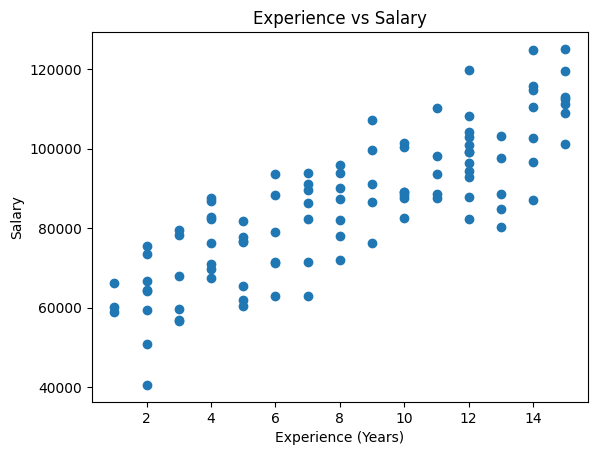

In [11]:
import matplotlib.pyplot as plt

plt.scatter(data["Experience"], data["Salary"])

plt.xlabel("Experience (Years)")
plt.ylabel("Salary")
plt.title("Experience vs Salary")

plt.show()

Check Correlation

In [12]:
correlation = data["Experience"].corr(data["Salary"])

print("Experience-Salary Correlation:", correlation)

Experience-Salary Correlation: 0.8297359235465199


In [13]:
correlations = data[
    ["Experience", "Skill_Score", "Job_Level", "Salary"]
].corr()

print(correlations)

             Experience  Skill_Score  Job_Level    Salary
Experience     1.000000     0.032268  -0.092394  0.829736
Skill_Score    0.032268     1.000000  -0.016529  0.268767
Job_Level     -0.092394    -0.016529   1.000000  0.317844
Salary         0.829736     0.268767   0.317844  1.000000


In [14]:
salary_correlations = data[
    ["Experience", "Skill_Score", "Job_Level", "Salary"]
].corr()["Salary"]

print(salary_correlations)

Experience     0.829736
Skill_Score    0.268767
Job_Level      0.317844
Salary         1.000000
Name: Salary, dtype: float64


Categorical Data Check

In [15]:
department_salary = (
    data.groupby("Department")["Salary"]
    .mean()
    .sort_values(ascending=False)
)

print(department_salary)

Department
Finance    91869.852941
IT         87567.555556
Sales      86335.125000
HR         75617.478261
Name: Salary, dtype: float64


In [16]:
print(data["Department"].value_counts())

Department
Finance    34
IT         27
HR         23
Sales      16
Name: count, dtype: int64


In [17]:
department_summary = data.groupby("Department").agg(
    Employee_Count=("Salary", "count"),
    Average_Experience=("Experience", "mean"),
    Average_Skill=("Skill_Score", "mean"),
    Average_Job_Level=("Job_Level", "mean"),
    Average_Salary=("Salary", "mean")
)

print(department_summary.round(2))

            Employee_Count  Average_Experience  Average_Skill  \
Department                                                      
Finance                 34                9.44          73.62   
HR                      23                6.96          72.39   
IT                      27                7.67          75.78   
Sales                   16                8.69          72.19   

            Average_Job_Level  Average_Salary  
Department                                     
Finance                  2.76        91869.85  
HR                       2.39        75617.48  
IT                       2.59        87567.56  
Sales                    2.88        86335.12  


Check Duplicates

In [18]:
## Check duplicates

duplicates = data.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


***3. Building the ML model***

**1. Define X and y**

In [19]:
X = data[
    ["Experience", "Skill_Score", "Job_Level", "Department"]
]

y = data["Salary"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFirst 5 rows of X:")
print(X.head())

print("\nFirst 5 values of y:")
print(y.head())

X shape: (100, 4)
y shape: (100,)

First 5 rows of X:
   Experience  Skill_Score  Job_Level Department
0           7           83          4    Finance
1           4           59          3    Finance
2          13           85          2         HR
3          15           63          4    Finance
4          11           80          1         IT

First 5 values of y:
0     93932.0
1     71003.0
2     97663.0
3    112874.0
4     88453.0
Name: Salary, dtype: float64


**2.Split BEFORE preprocessing**

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (80, 4)
X_test shape: (20, 4)
y_train shape: (80,)
y_test shape: (20,)


**3. Separate numerical and categorical columns**

In [21]:
numeric_features = [
    "Experience",
    "Skill_Score",
    "Job_Level"
]

categorical_features = [
    "Department"
]

print("Numerical:", numeric_features)
print("Categorical:", categorical_features)

Numerical: ['Experience', 'Skill_Score', 'Job_Level']
Categorical: ['Department']


**4. Numerical pipeline**

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print(numeric_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


**5. Categorical pipeline**

In [23]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

print(categorical_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder', OneHotEncoder(handle_unknown='ignore'))])


**6. ColumnTransformer**

In [24]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numeric_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Experience', 'Skill_Score', 'Job_Level']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Department'])])


**7. Connect preprocessing to Linear Regression**

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

linear_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

print(linear_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Experience', 'Skill_Score',
                                                   'Job_Level']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='

In [26]:
linear_pipeline.fit(X_train, y_train)

y_pred_linear = linear_pipeline.predict(X_test)

print("First 5 predicted salaries:")
print(y_pred_linear[:5])

print("\nFirst 5 actual salaries:")
print(y_test.iloc[:5].values)

First 5 predicted salaries:
[ 68550.59062788  97709.47815687  76070.94433193 117486.60620783
  98455.88435722]

First 5 actual salaries:
[ 66145.  99536.  76400. 114819. 101214.]


In [27]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

mae_linear = mean_absolute_error(
    y_test,
    y_pred_linear
)

mse_linear = mean_squared_error(
    y_test,
    y_pred_linear
)

rmse_linear = np.sqrt(mse_linear)

r2_linear = r2_score(
    y_test,
    y_pred_linear
)

print("Linear Regression MAE:", mae_linear)
print("Linear Regression MSE:", mse_linear)
print("Linear Regression RMSE:", rmse_linear)
print("Linear Regression R2:", r2_linear)

Linear Regression MAE: 3419.0582523091557
Linear Regression MSE: 14337928.68974359
Linear Regression RMSE: 3786.54574642161
Linear Regression R2: 0.9583324372479256


In [28]:
y_train_pred = linear_pipeline.predict(X_train)

train_mae = mean_absolute_error(
    y_train,
    y_train_pred
)

train_r2 = r2_score(
    y_train,
    y_train_pred
)

test_mae = mean_absolute_error(
    y_test,
    y_pred_linear
)

test_r2 = r2_score(
    y_test,
    y_pred_linear
)

print("Training MAE:", train_mae)
print("Testing MAE:", test_mae)

print("\nTraining R2:", train_r2)
print("Testing R2:", test_r2)

Training MAE: 3780.607698385298
Testing MAE: 3419.0582523091557

Training R2: 0.9229369285160826
Testing R2: 0.9583324372479256


**8. Cross-validation**

In [29]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    linear_pipeline,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

print("Raw CV scores:")
print(cv_scores)

cv_mae = -cv_scores

print("\nMAE for each fold:")
print(cv_mae)

print("\nAverage CV MAE:", cv_mae.mean())
print("CV MAE Standard Deviation:", cv_mae.std())

Raw CV scores:
[-4925.5459952  -3729.11794949 -4169.14772845 -4187.97420511
 -4114.11306931]

MAE for each fold:
[4925.5459952  3729.11794949 4169.14772845 4187.97420511 4114.11306931]

Average CV MAE: 4225.179789512809
CV MAE Standard Deviation: 388.188056208183


**9. Create the KNN pipeline**

In [30]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline

knn_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", KNeighborsRegressor())
    ]
)

print(knn_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Experience', 'Skill_Score',
                                                   'Job_Level']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='

**Hyper parameter Tuning GridSearchCV**

In [31]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__n_neighbors": [1, 3, 5, 7, 9, 11]
}

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_absolute_error"
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV score:", grid_search.best_score_)
print("Best CV MAE:", -grid_search.best_score_)

Best parameters: {'model__n_neighbors': 5}
Best CV score: -6303.325
Best CV MAE: 6303.325


Inspect every K value

In [32]:
results = grid_search.cv_results_

for k, score in zip(
    results["param_model__n_neighbors"],
    results["mean_test_score"]
):
    print(
        "K =", k,
        "| CV MAE =", round(-score, 2)
    )

K = 1 | CV MAE = 8447.42
K = 3 | CV MAE = 6788.4
K = 5 | CV MAE = 6303.32
K = 7 | CV MAE = 6342.9
K = 9 | CV MAE = 6639.32
K = 11 | CV MAE = 6673.84


In [33]:
best_knn = grid_search.best_estimator_

print(best_knn)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Experience', 'Skill_Score',
                                                   'Job_Level']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='

In [34]:
knn_test_pred = best_knn.predict(X_test)

knn_test_mae = mean_absolute_error(
    y_test,
    knn_test_pred
)

knn_test_rmse = np.sqrt(
    mean_squared_error(y_test, knn_test_pred)
)

knn_test_r2 = r2_score(
    y_test,
    knn_test_pred
)

print("KNN Test MAE:", knn_test_mae)
print("KNN Test RMSE:", knn_test_rmse)
print("KNN Test R2:", knn_test_r2)

KNN Test MAE: 8019.4800000000005
KNN Test RMSE: 9935.712330779308
KNN Test R2: 0.7131137723976047


Error analysis

In [35]:
results_df = X_test.copy()

results_df["Actual_Salary"] = y_test
results_df["Predicted_Salary"] = y_pred_linear

results_df["Absolute_Error"] = abs(
    results_df["Actual_Salary"]
    - results_df["Predicted_Salary"]
)

results_df = results_df.sort_values(
    "Absolute_Error",
    ascending=False
)

print(
    results_df[
        [
            "Experience",
            "Skill_Score",
            "Job_Level",
            "Department",
            "Actual_Salary",
            "Predicted_Salary",
            "Absolute_Error"
        ]
    ].round(2)
)

    Experience  Skill_Score  Job_Level Department  Actual_Salary  \
12          11           94          1    Finance        87472.0   
30           1           73          3         IT        60183.0   
18           8           90          3         IT        90165.0   
80          15           72          2    Finance       111246.0   
4           11           80          1         IT        88453.0   
22           2           50          1         HR        40584.0   
77          12           53          4      Sales       100991.0   
10           3           70          4    Finance        78176.0   
73          12           62          1         IT        94280.0   
76           7           81          3    Finance        89589.0   
44          15           57          2      Sales       101214.0   
45          14           61          5         IT       114819.0   
31          12           60          1         IT        87725.0   
33           6           57          1         I

In [36]:
results_df["Residual"] = (
    results_df["Actual_Salary"]
    - results_df["Predicted_Salary"]
)

print(
    results_df[
        [
            "Actual_Salary",
            "Predicted_Salary",
            "Residual"
        ]
    ].head(10).round(2)
)

    Actual_Salary  Predicted_Salary  Residual
12        87472.0          94598.28  -7126.28
30        60183.0          66387.88  -6204.88
18        90165.0          95883.03  -5718.03
80       111246.0         106506.19   4739.81
4         88453.0          93154.57  -4701.57
22        40584.0          44845.22  -4261.22
77       100991.0          96802.59   4188.41
10        78176.0          74397.42   3778.58
73        94280.0          90974.38   3305.62
76        89589.0          86674.64   2914.36


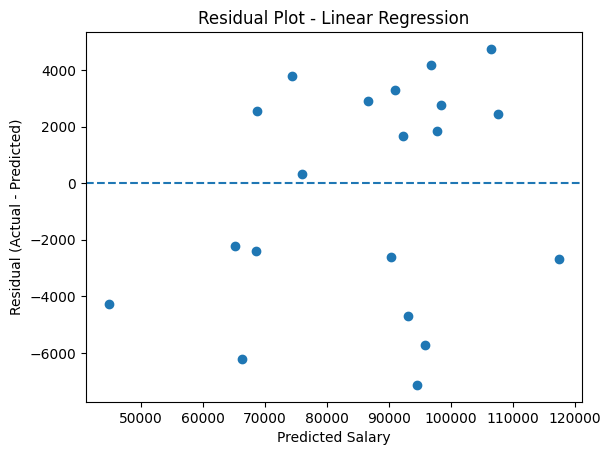

In [37]:
import matplotlib.pyplot as plt

plt.scatter(
    results_df["Predicted_Salary"],
    results_df["Residual"]
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Salary")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot - Linear Regression")

plt.show()

Create the Decision Tree model

In [79]:
from sklearn.tree import DecisionTreeRegressor

tree_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=3,
        random_state=42
    ))
])

tree_pipeline.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


Predict employee salaries.

In [80]:
y_pred_tree = tree_pipeline.predict(X_test)

print("Actual Salaries:")
print(y_test)

print("\nPredicted Salaries:")
print(y_pred_tree)

Actual Salaries:
83     66145.0
53     99536.0
70     76400.0
45    114819.0
44    101214.0
39    110093.0
22     40584.0
80    111246.0
10     78176.0
0      93932.0
18     90165.0
30     60183.0
73     94280.0
33     71228.0
90     63025.0
4      88453.0
76     89589.0
77    100991.0
12     87472.0
31     87725.0
Name: Salary, dtype: float64

Predicted Salaries:
[ 61709.72727273 100174.36363636  83490.27777778 114672.33333333
  91862.         100174.36363636  61709.72727273 114672.33333333
  61709.72727273  83490.27777778  83490.27777778  61709.72727273
  90478.1875      71017.36363636  71017.36363636  90478.1875
  83490.27777778  90478.1875     100174.36363636  90478.1875    ]


Evaluate the Decision Tree

In [81]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

mae_tree = mean_absolute_error(y_test, y_pred_tree)

rmse_tree = np.sqrt(
    mean_squared_error(y_test, y_pred_tree)
)

r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree MAE:", mae_tree)
print("Decision Tree RMSE:", rmse_tree)
print("Decision Tree R²:", r2_tree)

Decision Tree MAE: 6866.990404040404
Decision Tree RMSE: 8776.160064740743
Decision Tree R²: 0.7761687329292216


Tune the Decision Tree

In [82]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__max_depth": [2, 3, 4, 5, 6, 8]
}

grid_search = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

Best parameters: {'model__max_depth': 3}
Best CV MAE: 9548.63160397813


Get the best model

In [83]:
best_tree = grid_search.best_estimator_

y_pred_best_tree = best_tree.predict(X_test)

In [84]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_best = mean_absolute_error(y_test, y_pred_best_tree)
rmse_best = np.sqrt(mean_squared_error(y_test, y_pred_best_tree))
r2_best = r2_score(y_test, y_pred_best_tree)

print("Tuned Decision Tree MAE:", mae_best)
print("Tuned Decision Tree RMSE:", rmse_best)
print("Tuned Decision Tree R²:", r2_best)

Tuned Decision Tree MAE: 6866.990404040404
Tuned Decision Tree RMSE: 8776.160064740743
Tuned Decision Tree R²: 0.7761687329292216


Save the project results

In [85]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "MAE": [3419, mae_best],
    "RMSE": [3787, rmse_best],
    "R2": [0.958, r2_best]
})

print(comparison)

               Model          MAE         RMSE        R2
0  Linear Regression  3419.000000  3787.000000  0.958000
1      Decision Tree  6866.990404  8776.160065  0.776169


Find feature importance

In [86]:
best_tree = grid_search.best_estimator_

importance = best_tree.named_steps["model"].feature_importances_

feature_names = best_tree.named_steps["preprocessor"].get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

                   Feature  Importance
0          num__Experience    0.846502
1         num__Skill_Score    0.098219
2           num__Job_Level    0.055279
3  cat__Department_Finance    0.000000
4       cat__Department_HR    0.000000
5       cat__Department_IT    0.000000
6    cat__Department_Sales    0.000000


Let's visualize the results

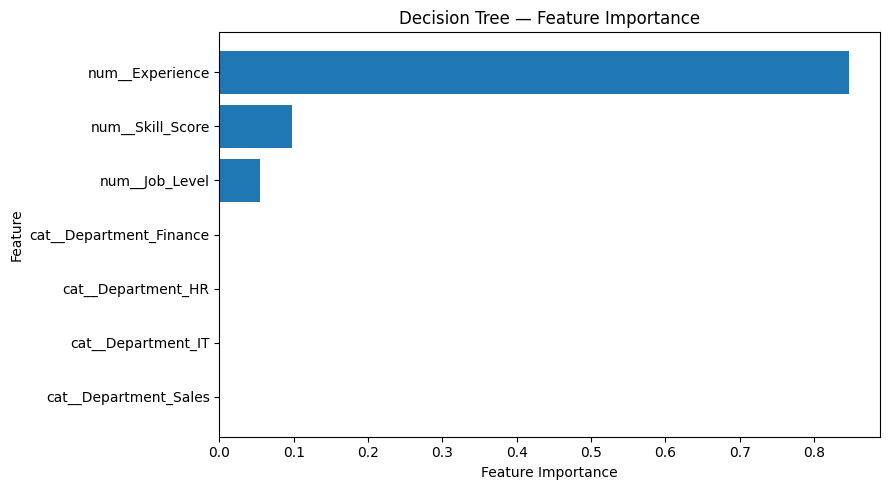

In [87]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Decision Tree — Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Residual Analysis

In [88]:
residuals = y_test - y_pred_best_tree

residual_df = pd.DataFrame({
    "Actual_Salary": y_test,
    "Predicted_Salary": y_pred_best_tree,
    "Residual": residuals
})

print(residual_df)

    Actual_Salary  Predicted_Salary      Residual
83        66145.0      61709.727273   4435.272727
53        99536.0     100174.363636   -638.363636
70        76400.0      83490.277778  -7090.277778
45       114819.0     114672.333333    146.666667
44       101214.0      91862.000000   9352.000000
39       110093.0     100174.363636   9918.636364
22        40584.0      61709.727273 -21125.727273
80       111246.0     114672.333333  -3426.333333
10        78176.0      61709.727273  16466.272727
0         93932.0      83490.277778  10441.722222
18        90165.0      83490.277778   6674.722222
30        60183.0      61709.727273  -1526.727273
73        94280.0      90478.187500   3801.812500
33        71228.0      71017.363636    210.636364
90        63025.0      71017.363636  -7992.363636
4         88453.0      90478.187500  -2025.187500
76        89589.0      83490.277778   6098.722222
77       100991.0      90478.187500  10512.812500
12        87472.0     100174.363636 -12702.363636


Let's verify which model produced these predictions

In [89]:
print("Linear Regression model:", type(linear_pipeline.named_steps["model"]))

print("\nLinear Regression predictions:")
print(linear_pipeline.predict(X_test)[:5])

print("\nDecision Tree predictions:")
print(tree_pipeline.predict(X_test)[:5])

Linear Regression model: <class 'sklearn.linear_model._base.LinearRegression'>

Linear Regression predictions:
[ 68550.59062788  97709.47815687  76070.94433193 117486.60620783
  98455.88435722]

Decision Tree predictions:
[ 61709.72727273 100174.36363636  83490.27777778 114672.33333333
  91862.        ]


Calculate Linear Regression residuals

In [90]:
import pandas as pd

# Generate Linear Regression predictions
y_pred_linear = linear_pipeline.predict(X_test)

# Create a comparison table
residual_df = pd.DataFrame({
    "Actual_Salary": y_test,
    "Predicted_Salary": y_pred_linear
})

residual_df["Residual"] = (
    residual_df["Actual_Salary"] -
    residual_df["Predicted_Salary"]
)

print(residual_df.round(2))

    Actual_Salary  Predicted_Salary  Residual
83        66145.0          68550.59  -2405.59
53        99536.0          97709.48   1826.52
70        76400.0          76070.94    329.06
45       114819.0         117486.61  -2667.61
44       101214.0          98455.88   2758.12
39       110093.0         107659.05   2433.95
22        40584.0          44845.22  -4261.22
80       111246.0         106506.19   4739.81
10        78176.0          74397.42   3778.58
0         93932.0          92280.16   1651.84
18        90165.0          95883.03  -5718.03
30        60183.0          66387.88  -6204.88
73        94280.0          90974.38   3305.62
33        71228.0          68688.51   2539.49
90        63025.0          65231.83  -2206.83
4         88453.0          93154.57  -4701.57
76        89589.0          86674.64   2914.36
77       100991.0          96802.59   4188.41
12        87472.0          94598.28  -7126.28
31        87725.0          90348.42  -2623.42


Visualize the residuals

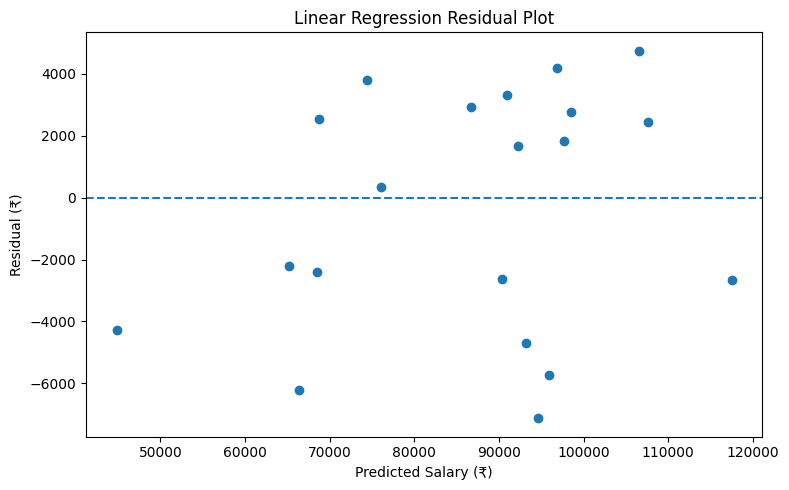

In [91]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(y_pred_linear, residual_df["Residual"])

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Salary (₹)")
plt.ylabel("Residual (₹)")
plt.title("Linear Regression Residual Plot")

plt.tight_layout()
plt.show()

Check the average residual

In [92]:
print("Mean Residual:", residual_df["Residual"].mean())
print("Mean Absolute Residual:", residual_df["Residual"].abs().mean())

Mean Residual: -372.4832416186306
Mean Absolute Residual: 3419.0582523091557


Linear Regression coefficients

In [93]:
# Get the trained Linear Regression model
linear_model = linear_pipeline.named_steps["model"]

# Get feature names after preprocessing
feature_names = linear_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Display coefficients
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": linear_model.coef_
})

coefficient_df = coefficient_df.sort_values(
    by="Coefficient",
    ascending=False
)

print("Intercept:", linear_model.intercept_)
print(coefficient_df)

Intercept: 85802.5113205083
                   Feature   Coefficient
0          num__Experience  14470.132581
2           num__Job_Level   6638.888810
5       cat__Department_IT   4267.527241
1         num__Skill_Score   4208.530873
3  cat__Department_Finance   1329.476250
6    cat__Department_Sales  -2026.090565
4       cat__Department_HR  -3570.912925


Reconstruct one prediction

In [94]:
# Select the first employee in the test dataset
employee = X_test.iloc[[0]]

# Predict using the trained model
prediction = linear_pipeline.predict(employee)[0]

print("Employee input:")
print(employee)

print("\nPredicted salary:", round(prediction, 2))

Employee input:
    Experience  Skill_Score  Job_Level Department
83           1           64          4         IT

Predicted salary: 68550.59


See how the pipeline transforms this employee

In [96]:
# Transform the employee's input using the preprocessor
employee_transformed = linear_pipeline.named_steps[
    "preprocessor"
].transform(employee)

# Get the transformed feature names
feature_names = linear_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Display the transformed values
transformed_df = pd.DataFrame(
    employee_transformed,
    columns=feature_names
)

print(transformed_df.round(3))

   num__Experience  num__Skill_Score  num__Job_Level  cat__Department_Finance  \
0           -1.727            -0.772           1.013                      0.0   

   cat__Department_HR  cat__Department_IT  cat__Department_Sales  
0                 0.0                 1.0                    0.0  


Verify the calculation with Python

In [97]:
import numpy as np

linear_model = linear_pipeline.named_steps["model"]

# Use the full-precision transformed values
contributions = (
    employee_transformed[0] * linear_model.coef_
)

calculated_salary = (
    linear_model.intercept_ + np.sum(contributions)
)

print("Intercept:", round(linear_model.intercept_, 2))
print("Sum of feature contributions:", round(np.sum(contributions), 2))
print("Calculated salary:", round(calculated_salary, 2))
print("Pipeline prediction:", round(prediction, 2))

Intercept: 85802.51
Sum of feature contributions: -17251.92
Calculated salary: 68550.59
Pipeline prediction: 68550.59


Make predictions for new employees

In [98]:
new_employees = pd.DataFrame({
    "Experience": [2, 5, 8],
    "Skill_Score": [70, 80, 90],
    "Job_Level": [2, 3, 5],
    "Department": ["IT", "Finance", "Sales"]
})

predicted_salaries = linear_pipeline.predict(new_employees)

new_employees["Predicted_Salary"] = predicted_salaries.round(2)

print(new_employees)

   Experience  Skill_Score  Job_Level Department  Predicted_Salary
0           2           70          2         IT          63922.87
1           5           80          3    Finance          79454.68
2           8           90          5      Sales          99548.52


In [99]:
# Predict with both trained models
linear_predictions = linear_pipeline.predict(new_employees)

tree_predictions = best_tree.predict(
    new_employees.drop(columns=["Predicted_Salary"])
)

# Compare the predictions
comparison_df = new_employees.drop(
    columns=["Predicted_Salary"]
).copy()

comparison_df["Linear_Regression"] = linear_predictions.round(2)
comparison_df["Decision_Tree"] = tree_predictions.round(2)

print(comparison_df)

   Experience  Skill_Score  Job_Level Department  Linear_Regression  \
0           2           70          2         IT           63922.87   
1           5           80          3    Finance           79454.68   
2           8           90          5      Sales           99548.52   

   Decision_Tree  
0       61709.73  
1       83490.28  
2       83490.28  


In [100]:
comparison_df["Absolute_Difference"] = (
    comparison_df["Linear_Regression"]
    - comparison_df["Decision_Tree"]
).abs()

comparison_df["Difference_Percentage"] = (
    comparison_df["Absolute_Difference"]
    / comparison_df["Linear_Regression"]
    * 100
).round(2)

print(comparison_df)

   Experience  Skill_Score  Job_Level Department  Linear_Regression  \
0           2           70          2         IT           63922.87   
1           5           80          3    Finance           79454.68   
2           8           90          5      Sales           99548.52   

   Decision_Tree  Absolute_Difference  Difference_Percentage  
0       61709.73              2213.14                   3.46  
1       83490.28              4035.60                   5.08  
2       83490.28             16058.24                  16.13  


## **`Final model validation`**

Compare training and test performance

In [101]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Predictions on training and test data
train_pred = linear_pipeline.predict(X_train)
test_pred = linear_pipeline.predict(X_test)

# Calculate metrics for both datasets
results = []

for dataset, actual, predicted in [
    ("Training", y_train, train_pred),
    ("Test", y_test, test_pred)
]:
    results.append({
        "Dataset": dataset,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2_Score": r2_score(actual, predicted)
    })

validation_df = pd.DataFrame(results)

print(validation_df.round(3))

    Dataset       MAE      RMSE  R2_Score
0  Training  3780.608  4786.068     0.923
1      Test  3419.058  3786.546     0.958


# Employee Salary Prediction Using Machine Learning

## Project Overview
Developed a supervised machine learning project to predict employee salaries using experience, skill score, job level, and department. Compared Linear Regression and Decision Tree models to evaluate their predictive performance.

## Objectives
- Prepare employee data for machine learning.
- Build and evaluate regression models.
- Compare model performance using MAE, RMSE, and R².
- Interpret model coefficients and feature importance.
- Generate salary predictions for new employee profiles.

## Technologies Used
- Python
- Pandas and NumPy
- Scikit-learn
- Matplotlib
- Linear Regression
- Decision Tree Regressor
- GridSearchCV and cross-validation

## Methodology
1. Prepared the dataset and separated input features from the target salary.
2. Built a preprocessing pipeline to standardize numerical features and encode department categories.
3. Split the data into training and test sets.
4. Trained Linear Regression and Decision Tree regression models.
5. Tuned Decision Tree depth using GridSearchCV.
6. Evaluated performance using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R².
7. Examined residuals, model coefficients, and Decision Tree feature importance.
8. Generated and compared predictions for new employee profiles.

## Linear Regression Results

| Metric | Training | Test |
|---|---:|---:|
| MAE | ₹3,780.61 | ₹3,419.06 |
| RMSE | ₹4,786.07 | ₹3,786.55 |
| R² | 0.923 | 0.958 |

Linear Regression outperformed the tuned Decision Tree on the recorded test results, making it the preferred candidate for this dataset.

## Key Findings
- Experience was the most important feature in the fitted Decision Tree, with a reported importance of approximately 0.847.
- Linear Regression achieved a test R² of 0.958 and a test MAE of approximately ₹3,419.
- Residual analysis and coefficient interpretation helped assess prediction errors and understand model behavior.
- The two models produced different estimates for some employee profiles, demonstrating how algorithm choice affects predictions.

## Limitations
The dataset is synthetic and contains a limited number of records. Results should not be generalized to real salary decisions without testing on representative real-world data, checking for bias, and validating performance on additional unseen samples.

## Conclusion
This project demonstrates an end-to-end regression workflow, from preprocessing and model training to evaluation, interpretation, and prediction. It provides practical experience with scikit-learn pipelines, regression metrics, cross-validation, and model comparison.
